C:\Users\tanuc\AppData\Local\Temp\ipykernel_6968\779799469.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Product", y="Total_Sales", data=df, palette=PRIMARY_PALETTE)
C:\Users\tanuc\AppData\Local\Temp\ipykernel_6968\779799469.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="Region", y="Price", data=df, palette=SECONDARY_PALETTE, inner="quartile")
C:\Users\tanuc\AppData\Local\Temp\ipykernel_6968\779799469.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Product", y="Total_Sales", data=df, ax=axes[0, 0], palette=PRIMA

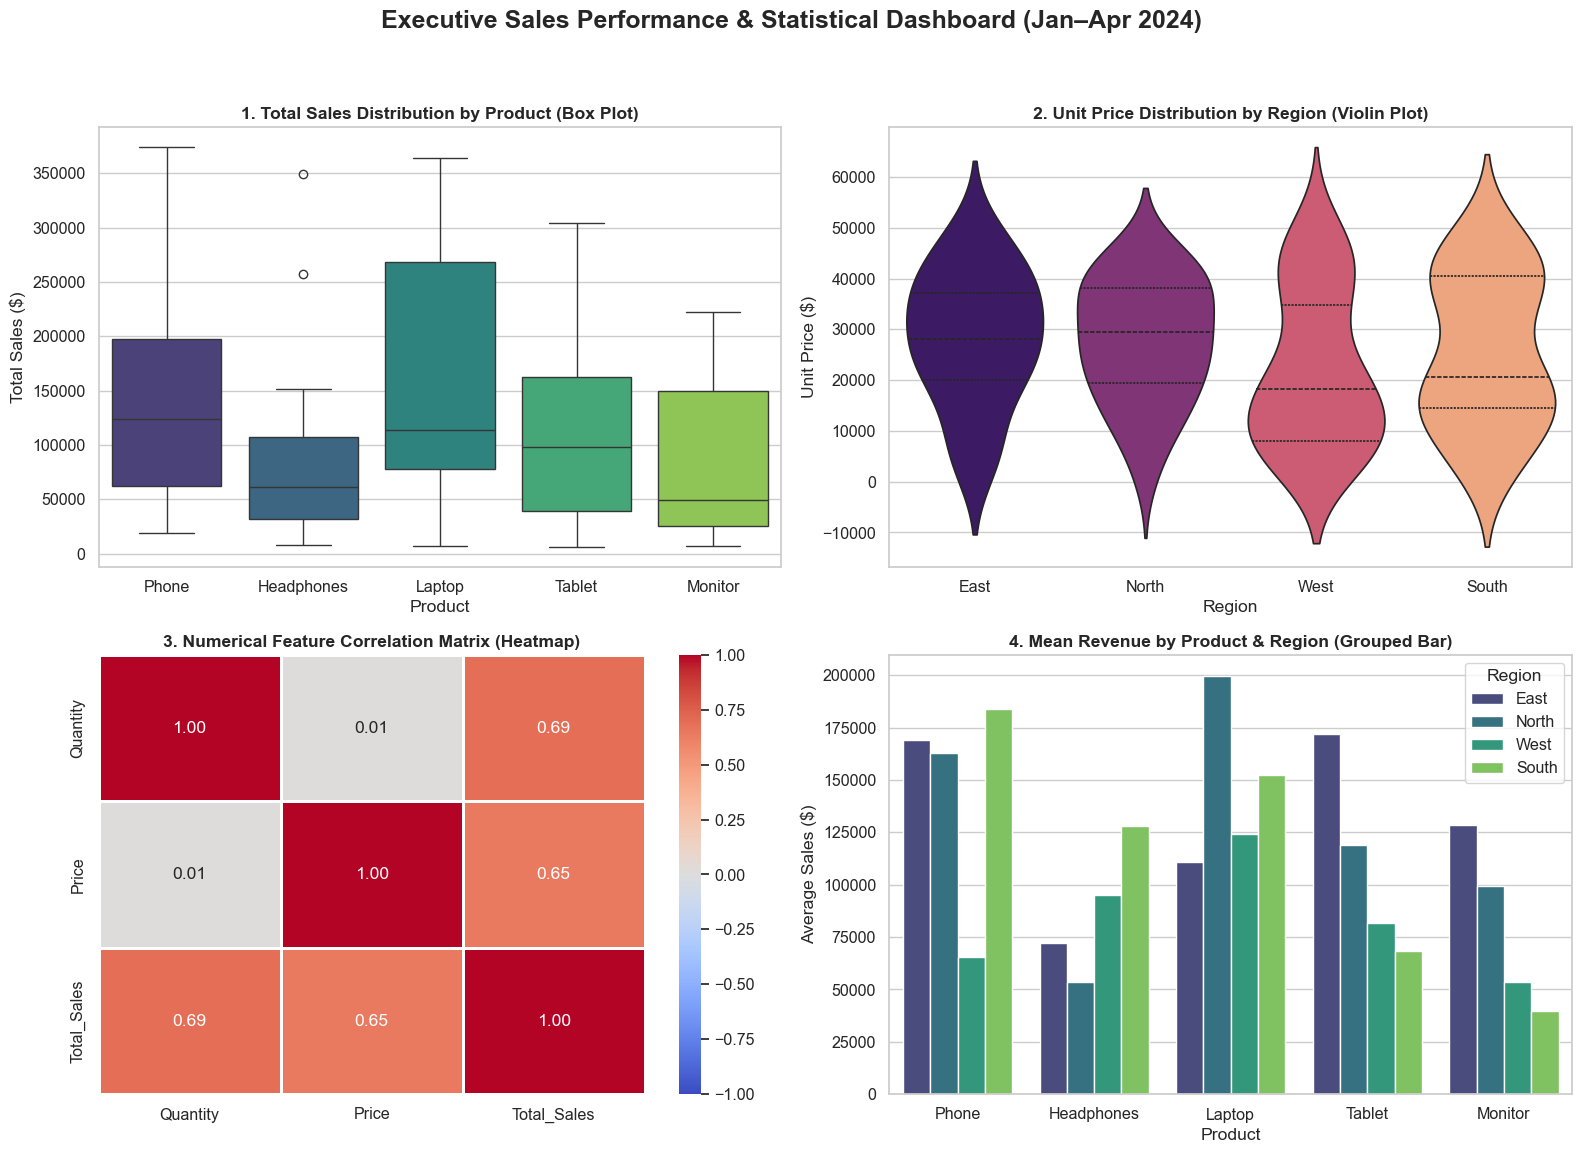

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Setup & Data Loading
os.makedirs("visualizations", exist_ok=True)
df = pd.read_csv("sales_data.csv")
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M").astype(str)

# Cohesive Theme Configuration
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
PRIMARY_PALETTE = "viridis"
SECONDARY_PALETTE = "magma"

# 2. Individual Chart Exports (Days 1-3)
# Chart 1: Box Plot (Total Sales by Product)
plt.figure(figsize=(9, 6))
sns.boxplot(x="Product", y="Total_Sales", data=df, palette=PRIMARY_PALETTE)
plt.title("Total Sales Distribution by Product", fontsize=14, fontweight="bold")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.savefig("visualizations/01_sales_boxplot.png", dpi=300)
plt.close()

# Chart 2: Violin Plot (Unit Price by Region)
plt.figure(figsize=(9, 6))
sns.violinplot(x="Region", y="Price", data=df, palette=SECONDARY_PALETTE, inner="quartile")
plt.title("Unit Price Density & Quartiles by Region", fontsize=14, fontweight="bold")
plt.xlabel("Sales Region")
plt.ylabel("Unit Price ($)")
plt.tight_layout()
plt.savefig("visualizations/02_price_violinplot.png", dpi=300)
plt.close()

# Chart 3: Correlation Heatmap
plt.figure(figsize=(7, 6))
corr_matrix = df[["Quantity", "Price", "Total_Sales"]].corr()
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=1.5, cbar_kws={"shrink": 0.8}
)
plt.title("Numerical Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("visualizations/03_correlation_heatmap.png", dpi=300)
plt.close()

# 3. Multi-Plot 2x2 Statistical Dashboard (Day 4)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Executive Sales Performance & Statistical Dashboard (Jan–Apr 2024)",
    fontsize=18, fontweight="bold", y=0.98
)

# Subplot 1: Box Plot
sns.boxplot(x="Product", y="Total_Sales", data=df, ax=axes[0, 0], palette=PRIMARY_PALETTE)
axes[0, 0].set_title("1. Total Sales Distribution by Product (Box Plot)", fontweight="bold")
axes[0, 0].set_ylabel("Total Sales ($)")

# Subplot 2: Violin Plot
sns.violinplot(x="Region", y="Price", data=df, ax=axes[0, 1], palette=SECONDARY_PALETTE, inner="quartile")
axes[0, 1].set_title("2. Unit Price Distribution by Region (Violin Plot)", fontweight="bold")
axes[0, 1].set_ylabel("Unit Price ($)")

# Subplot 3: Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 0], linewidths=1)
axes[1, 0].set_title("3. Numerical Feature Correlation Matrix (Heatmap)", fontweight="bold")

# Subplot 4: Grouped Bar Plot
sns.barplot(x="Product", y="Total_Sales", hue="Region", data=df, ax=axes[1, 1], palette=PRIMARY_PALETTE, errorbar=None)
axes[1, 1].set_title("4. Mean Revenue by Product & Region (Grouped Bar)", fontweight="bold")
axes[1, 1].set_ylabel("Average Sales ($)")
axes[1, 1].legend(title="Region", loc="upper right")

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig("visualizations/seaborn_statistical_dashboard.png", dpi=300)
plt.show()